# Walmart grocery forecasting with prophet-batch (local)

1,437 M5 FOODS items (each summed over Walmart's 10 stores), daily, 2011-01-29 to 2016-05-22. The last 28 days are
held out. This notebook:

1. loads the data,
2. shows the prophet-batch API on a sample (`fit_many` + `predict_many`),
3. shows the results of the full runs (`envs/local/run.sh`): accuracy and speed vs stock Prophet,
4. plots a few forecasts.

Setup (once, from the repo root): `uv sync`, then `uv run python -m walmart_grocery_forecasting.pipeline.data`.
Open with `uv run jupyter lab`.

In [1]:
import sys, time
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / 'pyproject.toml').exists():  # the notebook may be opened from any folder in the repo
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import logging
from IPython.display import Markdown, display
from walmart_grocery_forecasting.pipeline import data
from walmart_grocery_forecasting.pipeline.plots import plot_items

logging.getLogger('cmdstanpy').disabled = True
RUNS = ROOT / 'walmart_grocery_forecasting' / 'results' / 'runs'

## 1. Data

In [2]:
wide = data.load_items()
train, test = data.split(wide)
print(f'{len(wide):,} items × {wide.shape[1]:,} days; train {train.shape[1]:,}, test {test.shape[1]}')
wide.iloc[:5, -7:]

1,437 items × 1,941 days; train 1,913, test 28


ds,2016-05-16,2016-05-17,2016-05-18,2016-05-19,2016-05-20,2016-05-21,2016-05-22
item_id,,,,,,,
FOODS_1_001,4.0,7.0,7.0,5.0,7.0,5.0,9.0
FOODS_1_002,2.0,6.0,5.0,0.0,6.0,6.0,4.0
FOODS_1_003,11.0,9.0,7.0,7.0,10.0,6.0,5.0
FOODS_1_004,81.0,73.0,62.0,71.0,75.0,83.0,93.0
FOODS_1_005,9.0,7.0,25.0,19.0,25.0,17.0,19.0


## 2. prophet-batch on a sample

Long format in (`unique_id`, `ds`, `y`), one fitted `Prophet` per item out. Forecasts are seeded per series, so they
don't depend on `n_jobs`. `history_uncertainty='analytic'` gives exact intervals on the history rows without
sampling.

In [3]:
from prophet_batch import fit_many, predict_many

sample = data.to_long(train.sample(200, random_state=0))
t0 = time.perf_counter()
models = fit_many(sample, n_jobs=-1)
forecasts = predict_many(models, periods=28, seed=0, n_jobs=-1, history_uncertainty='analytic')
print(f'{len(models)} items: fit + forecast in {time.perf_counter() - t0:.1f} s')
item = next(iter(forecasts))
forecasts[item][['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail()

Importing plotly failed. Interactive plots will not work.


Importing plotly failed. Interactive plots will not work.
Importing plotly failed. Interactive plots will not work.
Importing plotly failed. Interactive plots will not work.
Importing plotly failed. Interactive plots will not work.
Importing plotly failed. Interactive plots will not work.
Importing plotly failed. Interactive plots will not work.


Importing plotly failed. Interactive plots will not work.
Importing plotly failed. Interactive plots will not work.
Importing plotly failed. Interactive plots will not work.
Importing plotly failed. Interactive plots will not work.


Importing plotly failed. Interactive plots will not work.
Importing plotly failed. Interactive plots will not work.
Importing plotly failed. Interactive plots will not work.
Importing plotly failed. Interactive plots will not work.
Importing plotly failed. Interactive plots will not work.
Importing plotly failed. Interactive plots will not work.
Importing plotly failed. Interactive plots will not work.
Importing plotly failed. Interactive plots will not work.
Importing plotly failed. Interactive plots will not work.


Importing plotly failed. Interactive plots will not work.


200 items: fit + forecast in 2.5 s


,ds,yhat,yhat_lower,yhat_upper
1936,2016-05-18,12.821905,6.833604,19.704009
1937,2016-05-19,13.161485,6.445941,19.554399
1938,2016-05-20,14.566801,8.081144,20.767195
1939,2016-05-21,16.189100,9.427827,22.058477
1940,2016-05-22,14.702445,8.346959,21.270849


## 3. Results of the full runs

The latest run of each model variant in `results/runs/` (written by `envs/local/run.sh`; see `pipeline/models.py`
for the variants).

In [4]:
latest = {}
for path in sorted(RUNS.glob('local-*-1437-*.md')):
    latest[path.name.split('-')[1]] = path  # later timestamps overwrite earlier ones
for model, path in latest.items():
    display(Markdown(path.read_text()))

# walmart_grocery_forecasting: 1,437 M5 FOODS items, 28-day holdout

2026-10-21T10:28:08 · Apple M4 (10 logical CPUs) · macOS-26.5.2-arm64-arm-64bit · Python 3.12.13 · prophet 1.5.0 · prophet-batch 0.1.0.dev0 (3150f51) · examples a30ae9e+dirty

Model: `default` (see pipeline/models.py)

## Speed (fit + forecast of history and 28 days)

| method | workers | fit s | forecast s | total s | vs stock pool |
|---|---:|---:|---:|---:|---:|
| stock_serial (timed on 30, extrapolated) | 1 | 194.0 | 119.8 | 313.8 | 0.2× |
| stock_pool | 10 | 33.9 | 22.0 | 55.9 | 1.0× |
| batch_sampled | 1 | 6.1 | 65.2 | 71.3 | 0.8× |
| batch_analytic | 1 | 6.1 | 8.7 | 14.7 | 3.8× |
| batch_sampled | 10 | 2.5 | 13.1 | 15.7 | 3.6× |
| batch_analytic | 10 | 2.5 | 2.9 | 5.5 | 10.2× |

## Accuracy on the 28 held-out days

| method | WAPE | sMAPE | MASE mean | MASE median | 80% coverage | Δ MASE vs stock (± 2 SE) |
|---|---:|---:|---:|---:|---:|---:|
| stock_pool (n_jobs=10) | 0.3446 | 48.43 | 1.4279 | 1.1069 | 0.722 | – |
| batch_sampled (n_jobs=10) | 0.3438 | 48.39 | 1.4261 | 1.1042 | 0.719 | -0.0018 ± 0.0023 |
| batch_analytic (n_jobs=10) | 0.3438 | 48.39 | 1.4261 | 1.1042 | 0.720 | -0.0018 ± 0.0023 |

## Checks

- batch_sampled: n_jobs=1 and n_jobs=10 forecasts bit-identical: True
- batch_analytic: n_jobs=1 and n_jobs=10 forecasts bit-identical: True
- log posterior ≥ Stan's (share of series, tol 1e-6): 1.0000
- log posterior gain over Stan (min / median): 0.0351 / 3.11
- series fit by Stan (fallbacks): 0


# walmart_grocery_forecasting: 1,437 M5 FOODS items, 28-day holdout

2026-10-21T10:31:27 · Apple M4 (10 logical CPUs) · macOS-26.5.2-arm64-arm-64bit · Python 3.12.13 · prophet 1.5.0 · prophet-batch 0.1.0.dev0 (3150f51) · examples a30ae9e+dirty

Model: `events` (see pipeline/models.py)

## Speed (fit + forecast of history and 28 days)

| method | workers | fit s | forecast s | total s | vs stock pool |
|---|---:|---:|---:|---:|---:|
| stock_serial (timed on 30, extrapolated) | 1 | 255.7 | 135.0 | 390.7 | 0.2× |
| stock_pool | 10 | 48.0 | 24.8 | 72.8 | 1.0× |
| batch_sampled | 1 | 9.0 | 69.2 | 78.2 | 0.9× |
| batch_analytic | 1 | 9.0 | 12.2 | 21.3 | 3.4× |
| batch_sampled | 10 | 3.2 | 14.2 | 17.4 | 4.2× |
| batch_analytic | 10 | 3.2 | 3.9 | 7.1 | 10.3× |

## Accuracy on the 28 held-out days

| method | WAPE | sMAPE | MASE mean | MASE median | 80% coverage | Δ MASE vs stock (± 2 SE) |
|---|---:|---:|---:|---:|---:|---:|
| stock_pool (n_jobs=10) | 0.3479 | 48.91 | 1.4388 | 1.1170 | 0.712 | – |
| batch_sampled (n_jobs=10) | 0.3470 | 48.87 | 1.4377 | 1.1197 | 0.710 | -0.0011 ± 0.0021 |
| batch_analytic (n_jobs=10) | 0.3470 | 48.87 | 1.4377 | 1.1197 | 0.710 | -0.0011 ± 0.0021 |

## Checks

- batch_sampled: n_jobs=1 and n_jobs=10 forecasts bit-identical: True
- batch_analytic: n_jobs=1 and n_jobs=10 forecasts bit-identical: True
- log posterior ≥ Stan's (share of series, tol 1e-6): 1.0000
- log posterior gain over Stan (min / median): 0.0432 / 3.04
- series fit by Stan (fallbacks): 0


# walmart_grocery_forecasting: 1,437 M5 FOODS items, 28-day holdout

2026-10-21T10:35:02 · Apple M4 (10 logical CPUs) · macOS-26.5.2-arm64-arm-64bit · Python 3.12.13 · prophet 1.5.0 · prophet-batch 0.1.0.dev0 (3150f51) · examples a30ae9e+dirty

Model: `events_snap` (see pipeline/models.py)

## Speed (fit + forecast of history and 28 days)

| method | workers | fit s | forecast s | total s | vs stock pool |
|---|---:|---:|---:|---:|---:|
| stock_serial (timed on 30, extrapolated) | 1 | 270.1 | 137.6 | 407.7 | 0.2× |
| stock_pool | 10 | 54.4 | 25.6 | 80.0 | 1.0× |
| batch_sampled | 1 | 11.1 | 70.5 | 81.6 | 1.0× |
| batch_analytic | 1 | 11.1 | 14.3 | 25.4 | 3.1× |
| batch_sampled | 10 | 4.1 | 15.1 | 19.3 | 4.2× |
| batch_analytic | 10 | 4.1 | 5.2 | 9.3 | 8.6× |

## Accuracy on the 28 held-out days

| method | WAPE | sMAPE | MASE mean | MASE median | 80% coverage | Δ MASE vs stock (± 2 SE) |
|---|---:|---:|---:|---:|---:|---:|
| stock_pool (n_jobs=10) | 0.3423 | 48.51 | 1.4238 | 1.1022 | 0.710 | – |
| batch_sampled (n_jobs=10) | 0.3415 | 48.46 | 1.4228 | 1.1025 | 0.708 | -0.0010 ± 0.0022 |
| batch_analytic (n_jobs=10) | 0.3415 | 48.46 | 1.4228 | 1.1025 | 0.709 | -0.0010 ± 0.0022 |

## Checks

- batch_sampled: n_jobs=1 and n_jobs=10 forecasts bit-identical: True
- batch_analytic: n_jobs=1 and n_jobs=10 forecasts bit-identical: True
- log posterior ≥ Stan's (share of series, tol 1e-6): 1.0000
- log posterior gain over Stan (min / median): 0.0357 / 2.8
- series fit by Stan (fallbacks): 0


# walmart_grocery_forecasting: 1,437 M5 FOODS items, 28-day holdout

2026-10-20T23:09:45 · Apple M4 (10 logical CPUs) · macOS-26.5.2-arm64-arm-64bit · Python 3.12.13 · prophet 1.5.0 · prophet-batch 0.1.0.dev0 (a891bd0) · examples b5414b1+dirty

Model: `default` (see pipeline/models.py)

## Speed (fit + forecast of history and 28 days)

| method | workers | fit s | forecast s | total s | vs stock pool |
|---|---:|---:|---:|---:|---:|
| stock_serial (timed on 30, extrapolated) | 1 | 187.0 | 118.8 | 305.8 | 0.2× |
| stock_pool | 10 | 31.9 | 21.0 | 52.8 | 1.0× |
| batch_sampled | 1 | 5.9 | 73.1 | 79.0 | 0.7× |
| batch_analytic | 1 | 5.9 | 16.1 | 22.0 | 2.4× |
| batch_sampled | 10 | 2.3 | 14.4 | 16.7 | 3.2× |
| batch_analytic | 10 | 2.3 | 4.3 | 6.6 | 8.0× |

## Accuracy on the 28 held-out days

| method | WAPE | sMAPE | MASE mean | MASE median | 80% coverage | Δ MASE vs stock (± 2 SE) |
|---|---:|---:|---:|---:|---:|---:|
| stock_pool (n_jobs=10) | 0.3446 | 48.43 | 1.4279 | 1.1069 | 0.722 | – |
| batch_sampled (n_jobs=10) | 0.3438 | 48.39 | 1.4261 | 1.1042 | 0.719 | -0.0018 ± 0.0023 |
| batch_analytic (n_jobs=10) | 0.3438 | 48.39 | 1.4261 | 1.1042 | 0.720 | -0.0018 ± 0.0023 |

## Checks

- batch_sampled: n_jobs=1 and n_jobs=10 forecasts bit-identical: True
- batch_analytic: n_jobs=1 and n_jobs=10 forecasts bit-identical: True
- log posterior ≥ Stan's (share of series, tol 1e-6): 1.0000
- log posterior gain over Stan (min / median): 0.0351 / 3.11
- series fit by Stan (fallbacks): 0


## 4. Forecasts

Two of the best-selling items, two typical ones and two slow movers, from the `default` run: the last 8 weeks of
history, the 28 held-out days, and both forecasts. The prophet-batch and stock lines mostly overlap: same model,
fitted to the exact optimum instead of Stan's L-BFGS stopping point.

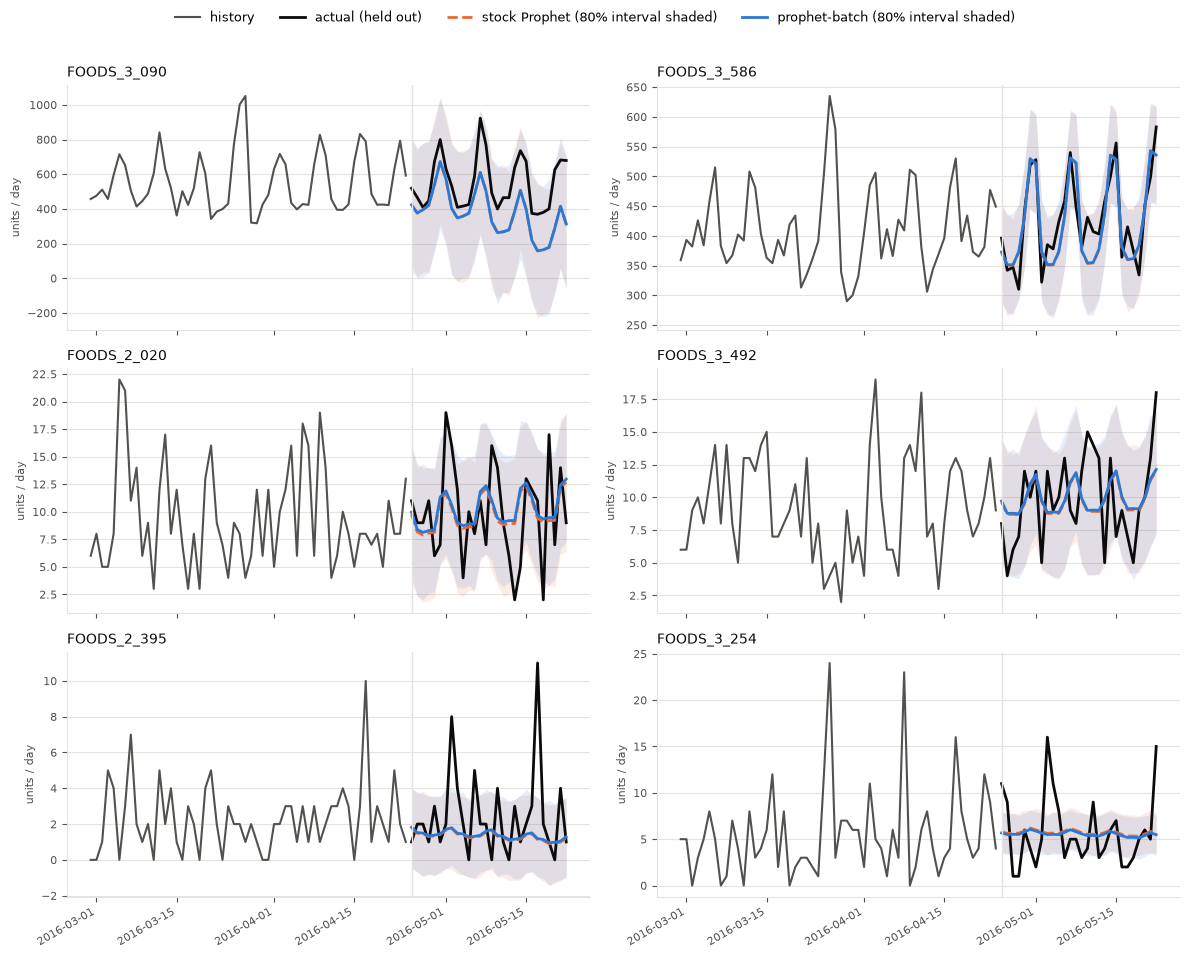

In [5]:
totals = train.sum(axis=1).sort_values()
items = list(totals.index[[-1, -2, len(totals) // 2, len(totals) // 2 + 1, 50, 51]])
fig = plot_items(latest['default'].with_suffix('.npz'), wide, items)